In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [57]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [58]:
# data split check
train_events = set(zip(train['Race'], train['Year']))
test_events = set(zip(test['Race'], test['Year']))
shared_events = train_events.intersection(test_events)

print(f"Unique events in train: {len(train_events)}")
print(f"Unique events in test: {len(test_events)}")
print(f"Shared events in both sets: {len(shared_events)}")


Unique events in train: 104
Unique events in test: 104
Shared events in both sets: 104


In [59]:
train.head()

,id,Driver,Compound,Race,Year,PitStop,LapNumber,Stint,TyreLife,Position,LapTime (s),LapTime_Delta,Cumulative_Degradation,RaceProgress,Position_Change,PitNextLap
0,0,D109,HARD,Canadian Grand Prix,2022,0,50,2,39.0,8,78.491,-7.564,21.019,0.714286,5.0,1.0
1,1,D086,HARD,Dutch Grand Prix,2025,1,27,2,7.0,4,75.095,-32.617,-223.207,0.346154,-3.0,0.0
2,2,ZON,HARD,Austrian Grand Prix,2022,0,59,3,22.0,13,70.945,-7.540,-100.529,0.819444,3.0,1.0
3,3,SPE,MEDIUM,Pre-Season Testing,2023,0,2,1,2.0,7,94.361,-7.324,-7.324,0.076923,0.0,0.0
4,4,D019,HARD,Azerbaijan Grand Prix,2022,1,26,3,6.0,2,107.878,8.965,-14.139,0.361111,3.0,0.0


In [60]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 439140 entries, 0 to 439139
Data columns (total 16 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   id                      439140 non-null  int64  
 1   Driver                  439140 non-null  object 
 2   Compound                439140 non-null  object 
 3   Race                    439140 non-null  object 
 4   Year                    439140 non-null  int64  
 5   PitStop                 439140 non-null  int64  
 6   LapNumber               439140 non-null  int64  
 7   Stint                   439140 non-null  int64  
 8   TyreLife                439140 non-null  float64
 9   Position                439140 non-null  int64  
 10  LapTime (s)             439140 non-null  float64
 11  LapTime_Delta           439140 non-null  float64
 12  Cumulative_Degradation  439140 non-null  float64
 13  RaceProgress            439140 non-null  float64
 14  Position_Change     

## Feature engineering

based on my knowledge as a formula 1 fan

In [61]:
# data concat for feature engineering
train['is_train'] = 1
test['is_train'] = 0
df = pd.concat([train, test], ignore_index=True)

# relative lap time to the fastest lap of the race
# normalization of lap times within each race and year
df['LapTime_Mean'] = df.groupby(['Race', 'Year'])['LapTime (s)'].transform('mean')
df['LapTime_Std'] = df.groupby(['Race', 'Year'])['LapTime (s)'].transform('std')
df['LapTime_Zscore'] = (df['LapTime (s)'] - df['LapTime_Mean']) / df['LapTime_Std']

# gap to the fastest lap of the current lap number
df['Fastest_LapTime_This_Lap'] = df.groupby(['Race', 'Year', 'LapNumber'])['LapTime (s)'].transform('min')
df['Gap_To_Fastest'] = df['LapTime (s)'] - df['Fastest_LapTime_This_Lap']

# max tyre life for each compound in each race and year
df['Track_Compound_Max_Life'] = df.groupby(['Race', 'Year', 'Compound'])['TyreLife'].transform('max')

# tire life normalized by the max tyre life for the compound in the race
df['Normalized_TyreLife'] = df['TyreLife'] / (df['Track_Compound_Max_Life'] + 1e-5)

# is the car obliged to pit soon?
df['Estimated_Total_Laps'] = df['LapNumber'] / (df['RaceProgress'] + 1e-5)
df['Estimated_Total_Laps'] = df.groupby(['Race', 'Year'])['Estimated_Total_Laps'].transform('median')
df['Laps_Remaining'] = df['Estimated_Total_Laps'] - df['LapNumber']
df['Must_Pit_Soon'] = ((df['PitStop'] == 0) & (df['RaceProgress'] > 0.8)).astype(int)

# degradation rate and cliff indicator
df['Degradation_Rate'] = df['Cumulative_Degradation'] / (df['TyreLife'] + 1e-5)
df['Cliff_Indicator'] = df['TyreLife'] * df['LapTime_Delta']



df.drop(columns=['LapTime_Mean', 'LapTime_Std', 'Fastest_LapTime_This_Lap', 'Track_Compound_Max_Life', 'Estimated_Total_Laps', 'Laps_Remaining'], inplace=True)

# categorical columns to category dtype
cat_cols = ['Driver', 'Compound', 'Race']
for col in cat_cols:
    df[col] = df[col].astype('category')

# float columns to float32 dtype to save memory
float_cols = df.select_dtypes(include=['float64']).columns
df[float_cols] = df[float_cols].astype('float32')

train_fe = df[df['is_train'] == 1].drop(columns=['is_train'])
test_fe = df[df['is_train'] == 0].drop(columns=['is_train', 'PitNextLap'])


## Data Analysis

In [62]:
train_fe.head()

,id,Driver,Compound,Race,Year,PitStop,LapNumber,Stint,TyreLife,Position,...,Cumulative_Degradation,RaceProgress,Position_Change,PitNextLap,LapTime_Zscore,Gap_To_Fastest,Normalized_TyreLife,Must_Pit_Soon,Degradation_Rate,Cliff_Indicator
0,0,D109,HARD,Canadian Grand Prix,2022,0,50,2,39.0,8,...,21.018999,0.714286,5.0,1.0,-0.496766,2.389,0.590909,0,0.538949,-294.996002
1,1,D086,HARD,Dutch Grand Prix,2025,1,27,2,7.0,4,...,-223.207001,0.346154,-3.0,0.0,-0.509679,0.655,0.101449,0,-31.886669,-228.319000
2,2,ZON,HARD,Austrian Grand Prix,2022,0,59,3,22.0,13,...,-100.528999,0.819444,3.0,1.0,-0.389274,2.236,0.468085,1,-4.569498,-165.880005
3,3,SPE,MEDIUM,Pre-Season Testing,2023,0,2,1,2.0,7,...,-7.324000,0.076923,0.0,0.0,-0.071532,3.814,0.040000,0,-3.661982,-14.648000
4,4,D019,HARD,Azerbaijan Grand Prix,2022,1,26,3,6.0,2,...,-14.139000,0.361111,3.0,0.0,-0.610202,3.268,0.130435,0,-2.356496,53.790001


In [63]:
train_fe.info()

<class 'pandas.core.frame.DataFrame'>
Index: 439140 entries, 0 to 439139
Data columns (total 22 columns):
 #   Column                  Non-Null Count   Dtype   
---  ------                  --------------   -----   
 0   id                      439140 non-null  int64   
 1   Driver                  439140 non-null  category
 2   Compound                439140 non-null  category
 3   Race                    439140 non-null  category
 4   Year                    439140 non-null  int64   
 5   PitStop                 439140 non-null  int64   
 6   LapNumber               439140 non-null  int64   
 7   Stint                   439140 non-null  int64   
 8   TyreLife                439140 non-null  float32 
 9   Position                439140 non-null  int64   
 10  LapTime (s)             439140 non-null  float32 
 11  LapTime_Delta           439140 non-null  float32 
 12  Cumulative_Degradation  439140 non-null  float32 
 13  RaceProgress            439140 non-null  float32 
 14  Position_

In [64]:
train_fe['PitNextLap'] = train_fe['PitNextLap'].astype(int)

In [65]:
train_fe.describe()

,id,Year,PitStop,LapNumber,Stint,TyreLife,Position,LapTime (s),LapTime_Delta,Cumulative_Degradation,RaceProgress,Position_Change,PitNextLap,LapTime_Zscore,Gap_To_Fastest,Normalized_TyreLife,Must_Pit_Soon,Degradation_Rate,Cliff_Indicator
count,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000,439140.000000
mean,219569.500000,2023.523544,0.136118,23.105909,1.789113,14.158231,9.630339,90.948753,-3.770040,-25.721764,0.337661,0.101542,0.198982,0.000429,7.750479,0.264184,0.064289,-3.014065,-37.893673
std,126768.942943,1.024930,0.342915,16.958261,0.950194,9.801338,5.278770,19.772770,43.945759,54.766571,0.253278,4.006765,0.399235,1.007717,18.265068,0.170336,0.245268,16.141899,205.052582
min,0.000000,2022.000000,0.000000,1.000000,1.000000,1.000000,1.000000,67.694000,-2403.895020,-274.563995,0.012821,-18.000000,0.000000,-9.493098,0.000000,0.012987,0.000000,-245.156555,-37215.023438
25%,109784.750000,2023.000000,0.000000,9.000000,1.000000,6.000000,5.000000,82.621002,-8.884000,-46.566252,0.129870,-1.000000,0.000000,-0.365033,2.247000,0.127273,0.000000,-4.516925,-86.695499
50%,219569.500000,2024.000000,0.000000,19.000000,2.000000,12.000000,10.000000,90.521004,-0.295000,-20.993999,0.269231,0.000000,0.000000,-0.178967,3.986000,0.240741,0.000000,-1.759192,-3.654000
75%,329354.250000,2024.000000,0.000000,36.000000,2.000000,20.000000,14.000000,98.471001,0.115000,-6.199000,0.513158,2.000000,0.000000,0.010270,10.729000,0.372549,0.000000,-0.476333,1.824000
max,439139.000000,2025.000000,1.000000,78.000000,8.000000,77.000000,20.000000,2507.606934,2423.931885,2412.025879,1.000000,18.000000,1.000000,83.692345,2432.785889,1.000000,1.000000,2409.975830,10110.000000


In [66]:
train_fe.describe(include='category')

,Driver,Compound,Race
count,439140,439140,439140
unique,887,5,26
top,MAS,MEDIUM,Dutch Grand Prix
freq,1682,211141,24462


In [67]:
train_fe.isna().sum()

id                        0
Driver                    0
Compound                  0
Race                      0
Year                      0
PitStop                   0
LapNumber                 0
Stint                     0
TyreLife                  0
Position                  0
LapTime (s)               0
LapTime_Delta             0
Cumulative_Degradation    0
RaceProgress              0
Position_Change           0
PitNextLap                0
LapTime_Zscore            0
Gap_To_Fastest            0
Normalized_TyreLife       0
Must_Pit_Soon             0
Degradation_Rate          0
Cliff_Indicator           0
dtype: int64

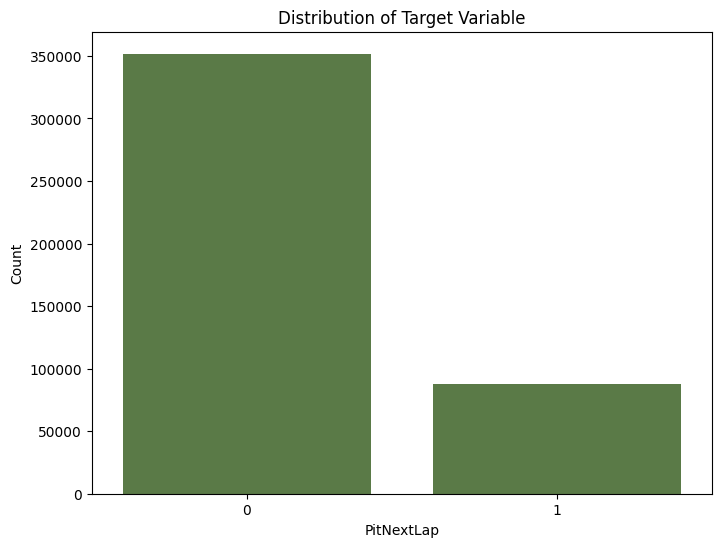

In [68]:
# target distribution
plt.figure(figsize=(8, 6))
sns.countplot(x='PitNextLap', data=train_fe, color='#58823e')
plt.title('Distribution of Target Variable')
plt.xlabel('PitNextLap')
plt.ylabel('Count')
plt.show()

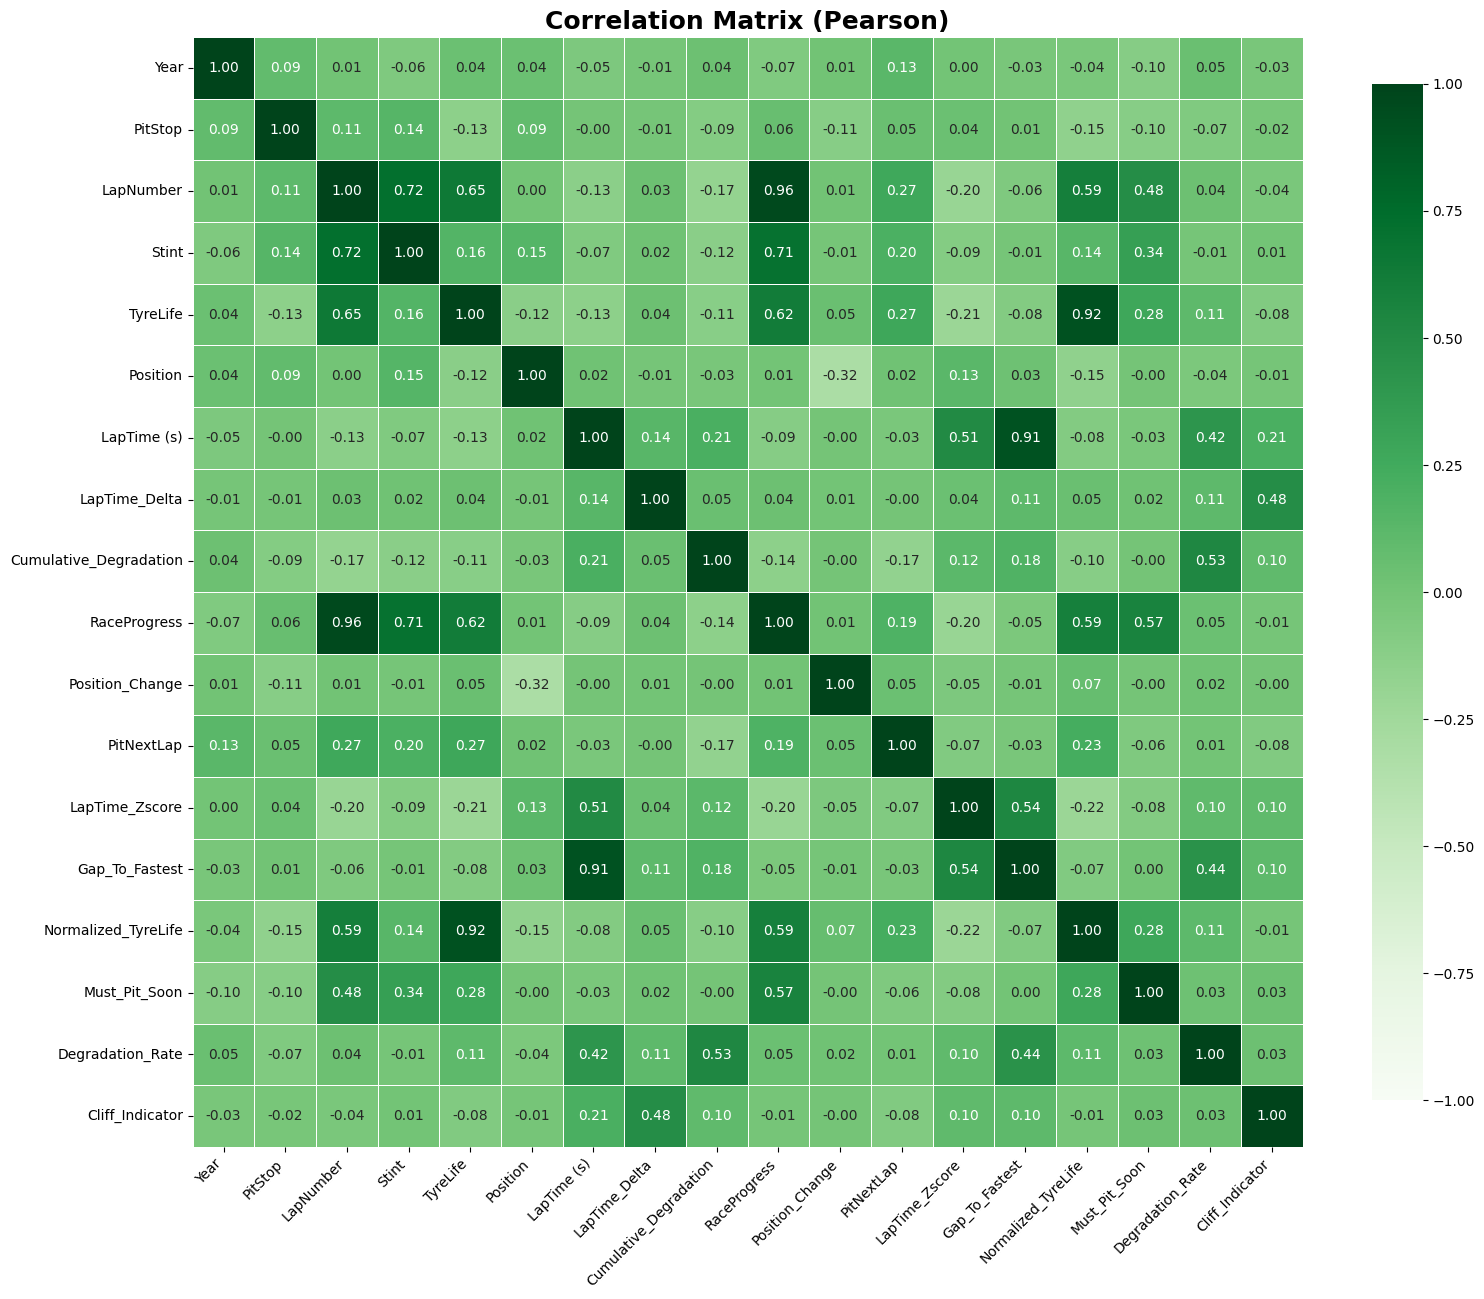


Correlation with target:
TyreLife                  0.273510
LapNumber                 0.267057
Normalized_TyreLife       0.230042
Stint                     0.198193
RaceProgress              0.185477
Cumulative_Degradation    0.167401
Year                      0.125267
Cliff_Indicator           0.076870
LapTime_Zscore            0.074641
Must_Pit_Soon             0.062480
PitStop                   0.048567
Position_Change           0.046230
LapTime (s)               0.034096
Gap_To_Fastest            0.028955
Position                  0.021348
Degradation_Rate          0.007807
LapTime_Delta             0.004946
Name: PitNextLap, dtype: float64


In [69]:
# correlation heatmap for numerical features
numeric_cols = train_fe.select_dtypes(include=['float32', 'float64', 'int32', 'int64']).drop(columns=['id'], errors='ignore')
corr_matrix = numeric_cols.corr()

plt.figure(figsize=(16, 14))
sns.heatmap(
    corr_matrix,  
    cmap='Greens',
    vmax=1.0, 
    vmin=-1.0, 
    center=0, 
    annot=True,
    fmt='.2f',
    square=True, 
    linewidths=.5, 
    cbar_kws={"shrink": .8}
)

plt.title('Correlation Matrix (Pearson)', fontsize=18, weight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# correlation with target 
print("\nCorrelation with target:")
target_corr = corr_matrix['PitNextLap'].drop('PitNextLap').abs().sort_values(ascending=False)
print(target_corr)

In [70]:
# deleting correlated features that bring little new information to the model
cols_to_drop = ['RaceProgress', 'LapTime (s)']

train_fe = train_fe.drop(columns=cols_to_drop)
test_fe = test_fe.drop(columns=cols_to_drop)

print(f"Number of columns in train_fe after cleaning: {train_fe.shape[1]}")
print(f"Number of columns in test_fe after cleaning: {test_fe.shape[1]}")


Number of columns in train_fe after cleaning: 20
Number of columns in test_fe after cleaning: 19


In [71]:
train_fe.to_csv('train_fe.csv', index=False)
test_fe.to_csv('test_fe.csv', index=False)

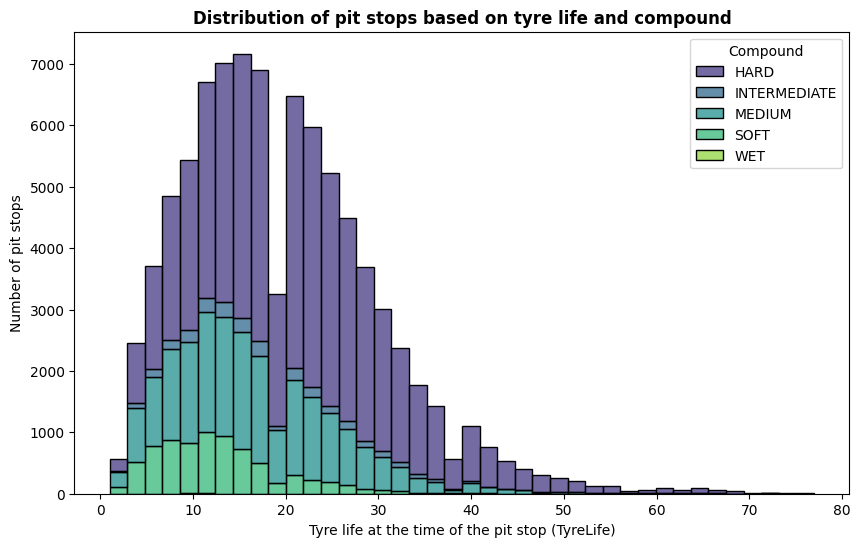

In [72]:
# Histogram of pit stops based on tyre life and compound
pit_stops = train_fe[train_fe['PitNextLap'] == 1]

plt.figure(figsize=(10, 6))
sns.histplot(
    data=pit_stops, 
    x='TyreLife', 
    hue='Compound', 
    multiple="stack", 
    bins=40, 
    palette="viridis"
)
plt.title("Distribution of pit stops based on tyre life and compound", weight="bold")
plt.xlabel("Tyre life at the time of the pit stop (TyreLife)")
plt.ylabel("Number of pit stops")
plt.show()

C:\Users\kinga\AppData\Local\Temp\ipykernel_26644\4294124191.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


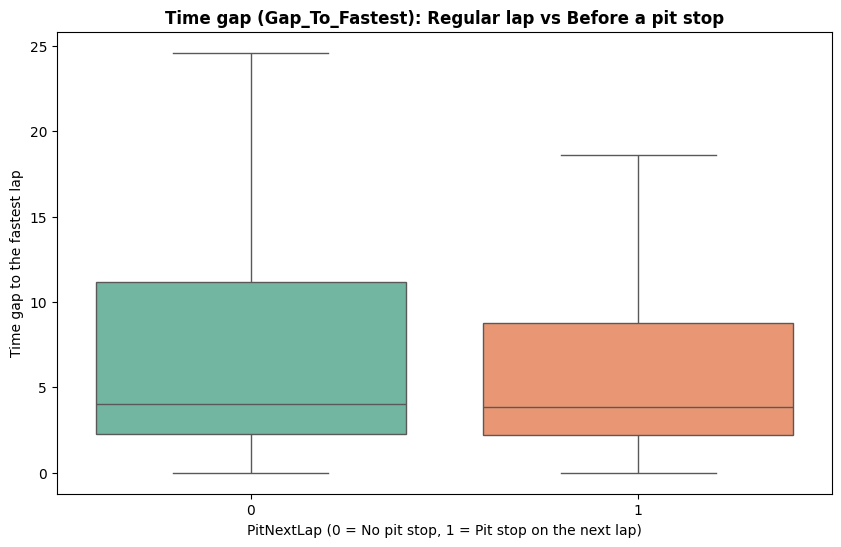

In [73]:
# Boxplot of Gap_To_Fastest based on PitNextLap
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=train_fe,
    x='PitNextLap',
    y='Gap_To_Fastest',
    showfliers=False, 
    palette='Set2'
)
plt.title("Time gap (Gap_To_Fastest): Regular lap vs Before a pit stop", weight="bold")
plt.xlabel("PitNextLap (0 = No pit stop, 1 = Pit stop on the next lap)")
plt.ylabel("Time gap to the fastest lap")
plt.show()

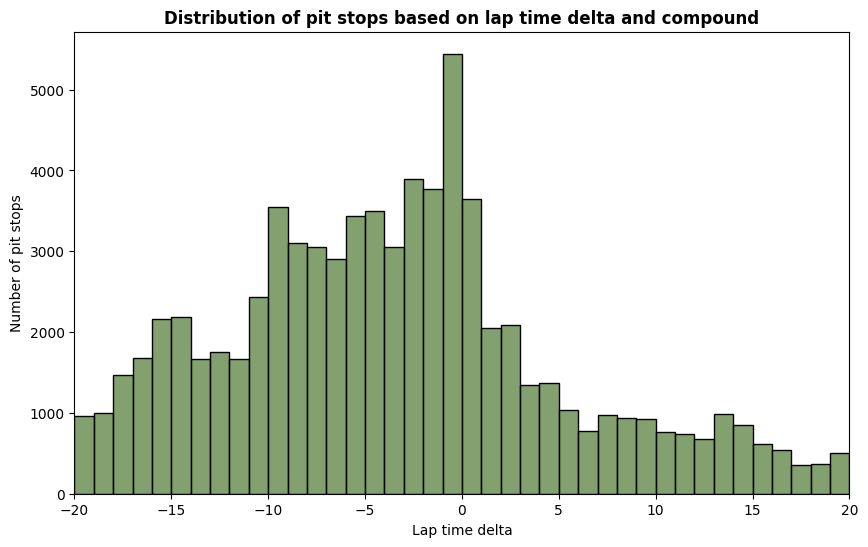

In [77]:
# Histogram of pit stops based on lap time delta
filtered_data = pit_stops[pit_stops['LapTime_Delta'].between(-20, 20)]

plt.figure(figsize=(10, 6))
sns.histplot(
    data=filtered_data, 
    x='LapTime_Delta', 
    bins=40, 
    binrange=(-20, 20),
    color="#58823e"
)
plt.xlim(-20, 20)
plt.title("Distribution of pit stops based on lap time delta and compound", weight="bold")
plt.xlabel("Lap time delta")
plt.ylabel("Number of pit stops")
plt.show()